# TAAPSHAMAN: Synthetic-Data Machine Learning Prototype

**Purpose:** predict daily maximum indoor temperature and derive a preliminary Thermal Resilience Score (TRS).

**Critical limitation:** the additional indoor measurements, envelope properties, and weather/environment variables were generated randomly using a transparent illustrative relationship. They are not real observations. The evaluation metrics measure how well the model learns this synthetic relationship, not real-world performance. Replace synthetic columns with observed data before drawing scientific conclusions.

## 1. Load the augmented dataset

Upload `taapshaman_synthetic_augmented_dataset.csv` to the Colab session, or set `DATA_PATH` to its location.

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = "/content/taapshaman_synthetic_augmented_dataset.csv"

if not os.path.exists(DATA_PATH):
    from google.colab import files
    uploaded = files.upload()
    DATA_PATH = next(
        name for name in uploaded if name.lower().endswith(".csv")
    )

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (1000, 29)


,Building ID,Height (m),Footprint Area (sq.m),Num. of Floors,Distance to City Center (km),Construction Material,Building Function,Region,Satellite Image Feature,Building Density,...,Air Conditioning (synthetic),"Outdoor Temperature Hot Day (C, synthetic)","Relative Humidity Hot Day (%, synthetic)","Solar Radiation (W/m2, synthetic)","Wind Speed (m/s, synthetic)","Tree Canopy Cover (%, synthetic)","Urban Heat Island Intensity (C, synthetic)","Daily Maximum Indoor Temperature (C, synthetic)","Indoor Temperature During Hot Day (C, synthetic)","Hours Above 28C (synthetic, 0-24)"
0,1,112,4389,15,3,Glass,Industrial,Central,"[0.8389973277180107, 0.011417983454073632, 0.7...",69,...,Yes,31.6,43.8,589.0,1.5,63.6,2.1,24.0,22.0,0.0
1,2,189,946,21,1,Brick,Public,Urban,"[0.0516687216579611, 0.5047955983045281, 0.718...",25,...,Yes,37.4,51.0,793.0,1.0,23.6,3.1,26.0,23.5,0.0
2,3,102,2862,19,4,Concrete,Residential,Industrial,"[0.15727320817971535, 0.30978785920909924, 0.2...",8,...,Partial,36.4,60.3,686.0,2.2,49.2,1.0,26.4,25.3,3.2
3,4,24,1241,29,2,Glass,Mixed-Use,Suburban,"[0.9060870604812605, 0.012156771477386807, 0.6...",7,...,Partial,37.3,62.3,387.0,1.7,18.7,2.9,24.9,23.7,0.0
4,5,116,1910,25,5,Wood,Commercial,Urban,"[0.7326990505902804, 0.4045273855738697, 0.068...",34,...,Yes,37.7,47.2,542.0,6.5,42.7,3.3,25.2,24.0,0.0



Columns:
['Building ID', 'Height (m)', 'Footprint Area (sq.m)', 'Num. of Floors', 'Distance to City Center (km)', 'Construction Material', 'Building Function', 'Region', 'Satellite Image Feature', 'Building Density', 'Zoning Classification', 'Land Use Type', 'Roof Material (synthetic)', 'Roof Colour (synthetic)', 'Wall Material (synthetic)', 'Roof Insulation (synthetic, mm)', 'Window Area Ratio (synthetic, %)', 'External Shading (synthetic)', 'Natural Ventilation (synthetic)', 'Air Conditioning (synthetic)', 'Outdoor Temperature Hot Day (C, synthetic)', 'Relative Humidity Hot Day (%, synthetic)', 'Solar Radiation (W/m2, synthetic)', 'Wind Speed (m/s, synthetic)', 'Tree Canopy Cover (%, synthetic)', 'Urban Heat Island Intensity (C, synthetic)', 'Daily Maximum Indoor Temperature (C, synthetic)', 'Indoor Temperature During Hot Day (C, synthetic)', 'Hours Above 28C (synthetic, 0-24)']


## 2. Define the prediction target and input features

The target is **Daily Maximum Indoor Temperature**. We intentionally exclude the other generated indoor outcome fields to avoid target leakage. `Building ID` is an identifier rather than a physical predictor, and the satellite feature vector is excluded until its meaning is documented.

In [13]:
TARGET = "Daily Maximum Indoor Temperature (C, synthetic)"

leakage_or_identifier_columns = [
    TARGET,
    "Indoor Temperature During Hot Day (C, synthetic)",
    "Hours Above 28C (synthetic, 0-24)",
    "Building ID",
    "Satellite Image Feature",
]

X = df.drop(columns=[
    col for col in leakage_or_identifier_columns if col in df.columns
])
y = pd.to_numeric(df[TARGET], errors="coerce")

valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].copy()

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(exclude=["number"]).columns.tolist()

print("Rows available:", len(X))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Rows available: 1000
Numeric features: ['Height (m)', 'Footprint Area (sq.m)', 'Num. of Floors', 'Distance to City Center (km)', 'Building Density', 'Roof Insulation (synthetic, mm)', 'Window Area Ratio (synthetic, %)', 'Outdoor Temperature Hot Day (C, synthetic)', 'Relative Humidity Hot Day (%, synthetic)', 'Solar Radiation (W/m2, synthetic)', 'Wind Speed (m/s, synthetic)', 'Tree Canopy Cover (%, synthetic)', 'Urban Heat Island Intensity (C, synthetic)']
Categorical features: ['Construction Material', 'Building Function', 'Region', 'Zoning Classification', 'Land Use Type', 'Roof Material (synthetic)', 'Roof Colour (synthetic)', 'Wall Material (synthetic)', 'External Shading (synthetic)', 'Natural Ventilation (synthetic)', 'Air Conditioning (synthetic)']


## 3. Preprocess, split, and train two models

The 80/20 holdout split is reproducible. Imputation and one-hot encoding are fitted inside the pipeline using training data only.

In [14]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=350, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=350, min_samples_leaf=2,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
}

trained_models = {}
metric_rows = []

for model_name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    metric_rows.append({
        "Model": model_name,
        "MAE (°C)": mean_absolute_error(y_test, predictions),
        "RMSE (°C)": mean_squared_error(y_test, predictions) ** 0.5,
        "R²": r2_score(y_test, predictions),
    })
    trained_models[model_name] = pipeline

metrics = pd.DataFrame(metric_rows).sort_values("RMSE (°C)")
display(metrics.round(3))

,Model,MAE (°C),RMSE (°C),R²
1,Extra Trees,0.961,1.231,0.630
0,Random Forest,1.015,1.302,0.586


## 4. Evaluate the best model

MAE and RMSE are expressed in degrees Celsius. R² indicates the proportion of test-set variance explained. Since targets are synthetic, these are **synthetic demonstration metrics**, not evidence of real-world accuracy.

Selected model: Extra Trees
Test MAE:  0.96 °C
Test RMSE: 1.23 °C
Test R²:   0.630


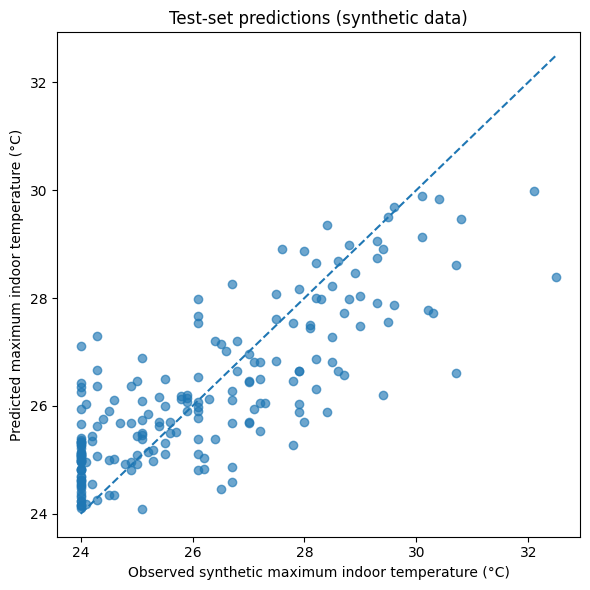

In [15]:
best_name = metrics.iloc[0]["Model"]
best_model = trained_models[best_name]
test_predictions = best_model.predict(X_test)

print("Selected model:", best_name)
print(f"Test MAE:  {mean_absolute_error(y_test, test_predictions):.2f} °C")
print(f"Test RMSE: {(mean_squared_error(y_test, test_predictions) ** 0.5):.2f} °C")
print(f"Test R²:   {r2_score(y_test, test_predictions):.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test, test_predictions, alpha=0.65)
limits = [
    min(y_test.min(), test_predictions.min()),
    max(y_test.max(), test_predictions.max())
]
plt.plot(limits, limits, linestyle="--")
plt.xlabel("Observed synthetic maximum indoor temperature (°C)")
plt.ylabel("Predicted maximum indoor temperature (°C)")
plt.title("Test-set predictions (synthetic data)")
plt.tight_layout()
plt.show()

## 5. Calculate a preliminary Thermal Resilience Score

For this prototype, the score is derived from predicted maximum indoor temperature using fixed illustrative reference bounds. A higher score means lower predicted overheating risk **within this prototype only**. It is not an established building-safety rating.

For research use, choose thresholds with local thermal-comfort guidance and validate them against real indoor measurements. Consider including observed hours above a comfort threshold once real data are available.

In [16]:
# Predict the target for every building
df["Predicted_Max_Indoor_Temperature_C"] = best_model.predict(X)

# Illustrative reference bounds only; not a universal comfort standard
LOW_TEMP_REFERENCE = 26.0
HIGH_TEMP_REFERENCE = 40.0

temp_risk = (
    (df["Predicted_Max_Indoor_Temperature_C"] - LOW_TEMP_REFERENCE)
    / (HIGH_TEMP_REFERENCE - LOW_TEMP_REFERENCE)
).clip(0, 1)

df["Thermal_Risk_Index_0_100"] = (100 * temp_risk).round(1)
df["Thermal_Resilience_Score_0_100"] = (
    100 - df["Thermal_Risk_Index_0_100"]
).round(1)

def risk_category(score):
    if score < 25:
        return "Low screening risk"
    elif score < 50:
        return "Moderate screening risk"
    elif score < 75:
        return "High screening risk"
    return "Very high screening risk"

df["TAAPSHAMAN_Screening_Category"] = (
    df["Thermal_Risk_Index_0_100"].apply(risk_category)
)

display(df[[
    "Building ID",
    TARGET,
    "Predicted_Max_Indoor_Temperature_C",
    "Thermal_Risk_Index_0_100",
    "Thermal_Resilience_Score_0_100",
    "TAAPSHAMAN_Screening_Category",
]].head(10))

,Building ID,"Daily Maximum Indoor Temperature (C, synthetic)",Predicted_Max_Indoor_Temperature_C,Thermal_Risk_Index_0_100,Thermal_Resilience_Score_0_100,TAAPSHAMAN_Screening_Category
0,1,24.0,24.055000,0.0,100.0,Low screening risk
1,2,26.0,26.003333,0.0,100.0,Low screening risk
2,3,26.4,26.470524,3.4,96.6,Low screening risk
3,4,24.9,25.020714,0.0,100.0,Low screening risk
4,5,25.2,25.226714,0.0,100.0,Low screening risk
5,6,24.0,24.087000,0.0,100.0,Low screening risk
6,7,24.0,24.034381,0.0,100.0,Low screening risk
7,8,27.3,27.233952,8.8,91.2,Low screening risk
8,9,27.4,27.260000,9.0,91.0,Low screening risk
9,10,24.9,24.992095,0.0,100.0,Low screening risk


## 6. Identify important predictors

Permutation importance estimates how much test-set model performance deteriorates when a feature is shuffled. It describes model reliance, not causation. With synthetic data, importance reflects the assumptions used to generate the synthetic target.

,Feature,Importance_MAE_Increase,Importance_Std
18,"Outdoor Temperature Hot Day (C, synthetic)",0.5363,0.0470
17,Air Conditioning (synthetic),0.3673,0.0275
14,"Window Area Ratio (synthetic, %)",0.1249,0.0145
13,"Roof Insulation (synthetic, mm)",0.0950,0.0111
10,Roof Material (synthetic),0.0640,0.0204
11,Roof Colour (synthetic),0.0580,0.0155
20,"Solar Radiation (W/m2, synthetic)",0.0435,0.0095
15,External Shading (synthetic),0.0257,0.0071
12,Wall Material (synthetic),0.0135,0.0058
16,Natural Ventilation (synthetic),0.0086,0.0047


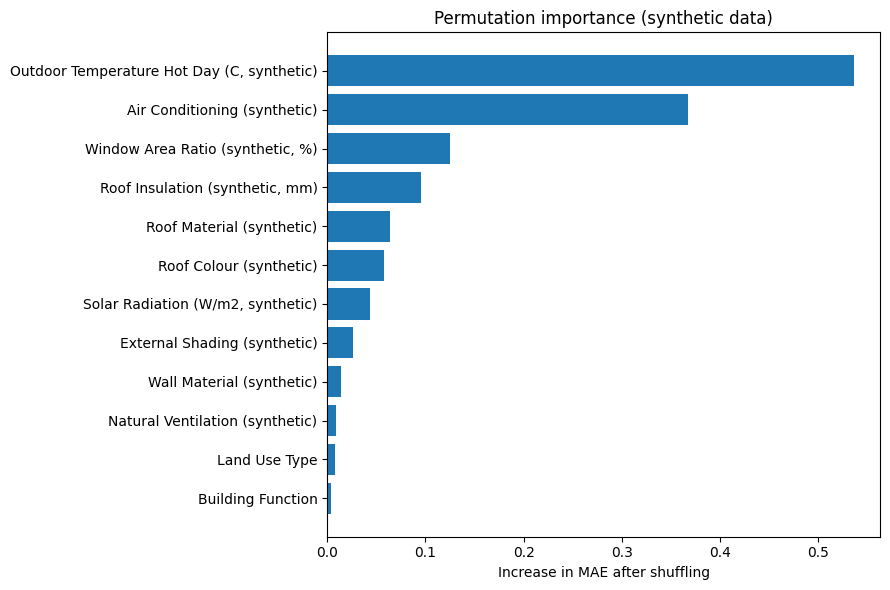

In [17]:
perm = permutation_importance(
    best_model, X_test, y_test,
    n_repeats=8, random_state=RANDOM_STATE,
    scoring="neg_mean_absolute_error", n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_MAE_Increase": perm.importances_mean,
    "Importance_Std": perm.importances_std,
}).sort_values("Importance_MAE_Increase", ascending=False)

display(importance.head(15).round(4))

top = importance.head(12).sort_values("Importance_MAE_Increase")
plt.figure(figsize=(9, 6))
plt.barh(top["Feature"], top["Importance_MAE_Increase"])
plt.xlabel("Increase in MAE after shuffling")
plt.title("Permutation importance (synthetic data)")
plt.tight_layout()
plt.show()

## 7. Generate transparent retrofit suggestions

These rules are screening prompts, not engineering prescriptions. Verify each building on site before recommending or pricing a retrofit.

In [18]:
def retrofit_suggestions(row):
    suggestions = []

    roof = str(row.get("Roof Material (synthetic)", "")).lower()
    colour = str(row.get("Roof Colour (synthetic)", "")).lower()
    insulation = row.get("Roof Insulation (synthetic, mm)", np.nan)
    shading = str(row.get("External Shading (synthetic)", "")).lower()
    ventilation = str(row.get("Natural Ventilation (synthetic)", "")).lower()
    ac = str(row.get("Air Conditioning (synthetic)", "")).lower()
    trees = row.get("Tree Canopy Cover (%, synthetic)", np.nan)

    if colour == "dark" or roof in ["metal sheet", "concrete slab"]:
        suggestions.append(
            "Inspect roof solar heat gain; assess a compatible reflective cool-roof treatment"
        )
    if pd.notna(insulation) and insulation < 20:
        suggestions.append(
            "Assess whether roof insulation is technically and economically suitable"
        )
    if shading == "none":
        suggestions.append(
            "Assess external shading for sun-exposed windows and walls"
        )
    if ventilation == "poor":
        suggestions.append(
            "Inspect safe cross-ventilation and night-purge options; check outdoor air quality and security"
        )
    if ac == "no":
        suggestions.append(
            "Assess passive cooling and access to safe cooling during extreme heat"
        )
    if pd.notna(trees) and trees < 15:
        suggestions.append(
            "Assess feasible tree canopy or other outdoor shade, considering water and space constraints"
        )

    if not suggestions:
        suggestions.append(
            "Conduct a building-envelope and indoor-temperature audit to identify the dominant heat pathway"
        )

    return "; ".join(suggestions)

df["Retrofit_Screening_Suggestions"] = df.apply(
    retrofit_suggestions, axis=1
)

# Save the scored buildings and model comparison
output_path = "/content/taapshaman_ml_scored_buildings.csv"
metrics_path = "/content/taapshaman_model_metrics.csv"

df.to_csv(output_path, index=False)
metrics.to_csv(metrics_path, index=False)

print("Saved:", output_path)
print("Saved:", metrics_path)

display(
    df.sort_values("Thermal_Risk_Index_0_100", ascending=False)[[
        "Building ID",
        "Predicted_Max_Indoor_Temperature_C",
        "Thermal_Risk_Index_0_100",
        "Thermal_Resilience_Score_0_100",
        "TAAPSHAMAN_Screening_Category",
        "Retrofit_Screening_Suggestions",
    ]].head(15)
)

Saved: /content/taapshaman_ml_scored_buildings.csv
Saved: /content/taapshaman_model_metrics.csv


,Building ID,Predicted_Max_Indoor_Temperature_C,Thermal_Risk_Index_0_100,Thermal_Resilience_Score_0_100,TAAPSHAMAN_Screening_Category,Retrofit_Screening_Suggestions
320,321,31.936714,42.4,57.6,Moderate screening risk,Assess whether roof insulation is technically ...
835,836,31.860286,41.9,58.1,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
273,274,31.628952,40.2,59.8,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
308,309,31.559429,39.7,60.3,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
798,799,31.548762,39.6,60.4,Moderate screening risk,Assess feasible tree canopy or other outdoor s...
347,348,31.435571,38.8,61.2,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
623,624,31.421286,38.7,61.3,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
813,814,31.318095,38.0,62.0,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
43,44,31.185238,37.0,63.0,Moderate screening risk,Inspect roof solar heat gain; assess a compati...
684,685,31.120714,36.6,63.4,Moderate screening risk,Inspect roof solar heat gain; assess a compati...


## 8. Export results from Google Colab

Run this cell to download the scored dataset and metrics.

In [19]:
from google.colab import files
files.download("/content/taapshaman_ml_scored_buildings.csv")
files.download("/content/taapshaman_model_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [20]:

# TAAPSHAMAN: Building-by-building thermal assessment
# Run this cell in Google Colab.

import io
import numpy as np
import pandas as pd
import ipywidgets as widgets

from google.colab import files
from IPython.display import display, clear_output
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# ---------------------------------------------------
# 1. LOAD THE TRAINING DATASET ONCE
# ---------------------------------------------------

print("Upload the TAAPSHAMAN augmented training CSV.")
uploaded = files.upload()

csv_name = next(
    (f for f in uploaded if f.lower().endswith(".csv")), None
)
if csv_name is None:
    raise ValueError("Upload a CSV training dataset.")

df = pd.read_csv(io.BytesIO(uploaded[csv_name]))

targets = [
    "Daily Maximum Indoor Temperature (C, synthetic)",
    "Indoor Temperature During Hot Day (C, synthetic)",
    "Hours Above 28C (synthetic, 0-24)"
]

missing = [c for c in targets if c not in df.columns]
if missing:
    raise ValueError(
        f"Missing target columns: {missing}. "
        "Use the augmented TAAPSHAMAN dataset."
    )

# Exclude identifiers, image-vector text, and all target variables.
excluded = ["Building ID", "Satellite Image Feature"] + targets
features = [c for c in df.columns if c not in excluded]

numeric_cols = [
    c for c in features
    if pd.api.types.is_numeric_dtype(df[c])
]
categorical_cols = [c for c in features if c not in numeric_cols]

# ---------------------------------------------------
# 2. TRAIN THREE INDEPENDENT MODELS
# ---------------------------------------------------

models = {}
metrics = {}

for target in targets:
    work = df[features + [target]].copy()
    work[target] = pd.to_numeric(work[target], errors="coerce")
    work = work.dropna(subset=[target])

    X = work[features]
    y = work[target]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )

    # Build a fresh preprocessing pipeline for each model.
    preprocess = ColumnTransformer([
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), numeric_cols),

        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_cols)
    ])

    model = Pipeline([
        ("preprocessing", preprocess),
        ("regressor", ExtraTreesRegressor(
            n_estimators=250,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ])

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    models[target] = model
    metrics[target] = {
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    }

print("\nAll three models are trained.")
print("These metrics are based on synthetic data, not real buildings.")

for target, result in metrics.items():
    print(
        f"\n{target}\n"
        f"MAE = {result['MAE']:.2f}; R² = {result['R2']:.3f}"
    )

# ---------------------------------------------------
# 3. BUILDING INPUT FORM
# ---------------------------------------------------

controls = {}

for col in features:
    if col in numeric_cols:
        series = pd.to_numeric(df[col], errors="coerce").dropna()
        default = float(series.median()) if len(series) else 0.0

        controls[col] = widgets.FloatText(
            value=round(default, 2),
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="98%")
        )
    else:
        choices = sorted(df[col].dropna().astype(str).unique().tolist())
        if not choices:
            choices = ["Unknown"]

        controls[col] = widgets.Dropdown(
            options=choices,
            value=choices[0],
            description=col,
            style={"description_width": "initial"},
            layout=widgets.Layout(width="98%")
        )

# Organise fields into useful sections.
sections = {
    "Building characteristics": [
        "Height (m)",
        "Footprint Area (sq.m)",
        "Num. of Floors",
        "Distance to City Center (km)",
        "Construction Material",
        "Building Function",
        "Region",
        "Building Density",
        "Zoning Classification",
        "Land Use Type"
    ],
    "Roof, walls, windows and ventilation": [
        "Roof Material (synthetic)",
        "Roof Colour (synthetic)",
        "Wall Material (synthetic)",
        "Roof Insulation (synthetic, mm)",
        "Window Area Ratio (synthetic, %)",
        "External Shading (synthetic)",
        "Natural Ventilation (synthetic)",
        "Air Conditioning (synthetic)"
    ],
    "Weather and surroundings": [
        "Outdoor Temperature Hot Day (C, synthetic)",
        "Relative Humidity Hot Day (%, synthetic)",
        "Solar Radiation (W/m2, synthetic)",
        "Wind Speed (m/s, synthetic)",
        "Tree Canopy Cover (%, synthetic)",
        "Urban Heat Island Intensity (C, synthetic)"
    ]
}

accordion_items = []
accordion_titles = []
included = set()

for section, cols in sections.items():
    existing = [c for c in cols if c in controls]
    if existing:
        accordion_items.append(
            widgets.VBox([controls[c] for c in existing])
        )
        accordion_titles.append(section)
        included.update(existing)

remaining = [c for c in features if c not in included]
if remaining:
    accordion_items.append(
        widgets.VBox([controls[c] for c in remaining])
    )
    accordion_titles.append("Additional features")

form = widgets.Accordion(children=accordion_items)
for i, title in enumerate(accordion_titles):
    form.set_title(i, title)

# ---------------------------------------------------
# 4. PREDICT A NEW BUILDING
# ---------------------------------------------------

predict_button = widgets.Button(
    description="Assess This Building",
    button_style="success",
    icon="check"
)

result_area = widgets.Output()

def assess_building(_):
    with result_area:
        clear_output(wait=True)

        # Collect current values from the form.
        row = {}
        for col in features:
            val = controls[col].value
            row[col] = float(val) if col in numeric_cols else str(val)

        new_building = pd.DataFrame([row], columns=features)

        # Generate estimates for this building.
        max_temp = float(
            models[targets[0]].predict(new_building)[0]
        )
        hot_temp = float(
            models[targets[1]].predict(new_building)[0]
        )
        hours_hot = float(
            models[targets[2]].predict(new_building)[0]
        )

        # Preliminary screening score, not an official standard.
        score = float(np.clip(
            100 * (40 - max_temp) / 14, 0, 100
        ))

        if score >= 75:
            rating = "Higher preliminary resilience"
        elif score >= 50:
            rating = "Moderate preliminary resilience"
        else:
            rating = "Lower preliminary resilience"

        print("=" * 55)
        print("TAAPSHAMAN BUILDING ASSESSMENT")
        print("=" * 55)

        print(f"\nPredicted daily maximum indoor temperature: "
              f"{max_temp:.1f} °C")
        print(f"Predicted indoor temperature during hot day: "
              f"{hot_temp:.1f} °C")
        print(f"Predicted hours above 28 °C: "
              f"{np.clip(hours_hot, 0, 24):.1f} hours/day")

        print(f"\nTHERMAL RESILIENCE SCORE: {score:.1f}/100")
        print("Screening category:", rating)

        # Generate screening suggestions from the submitted values.
        suggestions = []

        roof_colour = str(row.get(
            "Roof Colour (synthetic)", ""
        )).lower()
        insulation = row.get("Roof Insulation (synthetic, mm)", 0)
        shading = str(row.get(
            "External Shading (synthetic)", ""
        )).lower()
        ventilation = str(row.get(
            "Natural Ventilation (synthetic)", ""
        )).lower()
        window_ratio = row.get("Window Area Ratio (synthetic, %)", 0)
        tree_cover = row.get("Tree Canopy Cover (%, synthetic)", 0)
        outdoor_temp = row.get(
            "Outdoor Temperature Hot Day (C, synthetic)", 0
        )
        wall_material = str(row.get(
            "Wall Material (synthetic)", ""
        )).lower()

        if any(w in roof_colour for w in ["dark", "black"]):
            suggestions.append(
                "Evaluate a reflective, light-coloured roof coating."
            )
        if insulation < 50:
            suggestions.append(
                "Assess whether additional roof insulation is suitable."
            )
        if shading in ["none", "no", "low", "false"]:
            suggestions.append(
                "Evaluate external shading for sun-exposed windows."
            )
        if window_ratio > 30:
            suggestions.append(
                "Review window solar gain, glazing and external shading."
            )
        if ventilation in ["none", "no", "poor", "low", "false"]:
            suggestions.append(
                "Assess cross-ventilation or night ventilation where "
                "outdoor conditions permit."
            )
        if tree_cover < 20:
            suggestions.append(
                "Consider suitable tree cover and shaded outdoor areas."
            )
        if outdoor_temp > 30:
            suggestions.append(
                "Prioritise passive cooling and reduction of solar heat gain."
            )
        if "concrete" in wall_material and insulation < 50:
            suggestions.append(
                "Assess wall heat transfer and possible wall insulation."
            )
        if not suggestions:
            suggestions.append(
                "Review the envelope and ventilation using a site-specific "
                "energy or thermal assessment."
            )

        print("\nPOTENTIAL RETROFIT MEASURES")
        for i, suggestion in enumerate(suggestions, 1):
            print(f"{i}. {suggestion}")

        print("\nDATA AND MODEL LIMITATION")
        print(
            "The model was trained on synthetic outcomes. Its predictions, "
            "score and recommendations are illustrative only. They are "
            "not verified estimates for an actual building. Replace the "
            "synthetic training targets with measured indoor temperatures "
            "and validate the model before research or practical use."
        )

predict_button.on_click(assess_building)

print("\nEnter the details of the building you want to assess.")
print("Change the default values to match that building.")
display(form, predict_button, result_area)


Upload the TAAPSHAMAN augmented training CSV.


Saving taapshaman_synthetic_augmented_dataset.csv to taapshaman_synthetic_augmented_dataset (2).csv

All three models are trained.
These metrics are based on synthetic data, not real buildings.

Daily Maximum Indoor Temperature (C, synthetic)
MAE = 0.96; R² = 0.629

Indoor Temperature During Hot Day (C, synthetic)
MAE = 1.02; R² = 0.566

Hours Above 28C (synthetic, 0-24)
MAE = 1.88; R² = 0.483

Enter the details of the building you want to assess.
Change the default values to match that building.


Accordion(children=(VBox(children=(FloatText(value=108.0, description='Height (m)', layout=Layout(width='98%')…

Button(button_style='success', description='Assess This Building', icon='check', style=ButtonStyle())

Output()